# Dados e Aprendizagem Automática 26/27
### Part IX

## **K-means using Blobs Dataset - I**

#### Imports, installations and settings

Install *scikit-learn-extra*: <code>pip install https://github.com/scikit-learn-contrib/scikit-learn-extra/archive/master.zip</code>

In [1]:
!pip install https://github.com/scikit-learn-contrib/scikit-learn-extra/archive/master.zip

import sklearn as skl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

from sklearn import metrics

from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline

     \ 741.1 kB 894.6 kB/s 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0.dev0-cp314-cp314-macosx_12_0_arm64.whl size=388107 sha256=52fa0e25e1aa2a575c1d9e4e6e8c6579d60dc22423d6caf8750917c7488b2d17
  Stored in directory: /private/var/folders/qz/_w2k39tn2y35j2nb6g4w17wr0000gn/T/pip-ephem-wheel-cache-vsmrolau/wheels/b3/8f/29/2127591ab0133b64e2f5707d00db4dda6279b362208603c620
Successfully built scikit-learn-extra
  Attempting uninstall: scikit-learn-extra
    Found existing installation: scikit-learn-extra 0.3.0
    Uninstalling scikit-learn-extra-0.3.0:
      Successfully uninstalled scikit-learn-extra-0.3.0


#### Create the dataset using Blobs

In [2]:
data = make_blobs(n_samples = 200, n_features = 2, centers = 4, cluster_std = 1.8, random_state = 2022)

#### Define X and y

In [3]:
X = data[0]
y = data[1]

#### Visualize the data

View the first 5 lines of the data set:

In [4]:
print('X:', X[0:5, :])
print('y:', y[0:5])

X: [[  5.88508997   2.9021639 ]
 [ -8.20429992 -11.68670283]
 [  1.9125188   -2.76746603]
 [ -9.39601207  -7.2830252 ]
 [  6.1986976    7.32152342]]
y: [2 1 2 1 3]


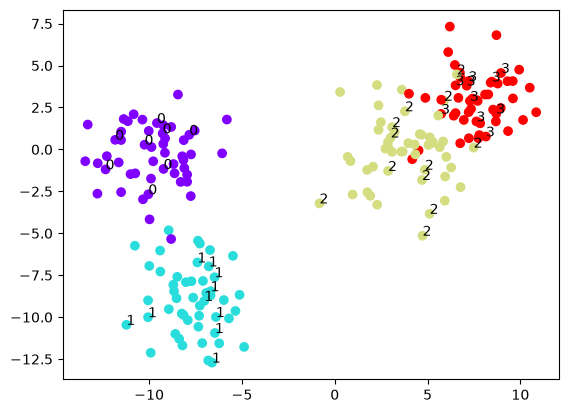

In [5]:
plt.scatter(X[:, 0], X[:, 1], c = y, cmap = 'rainbow')
for i, txt in enumerate(y):
    if i%5 == 0:
        plt.annotate(txt, (X[i, 0], X[i, 1]))

### Create the clusters

In [6]:
kmeans = KMeans(n_clusters = 4, n_init = 10, random_state = 2022)

In [7]:
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",2022
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 2)","[[-

Center of the 4 clusters

In [8]:
kmeans.cluster_centers_

array([[-7.68797564, -8.88054369],
       [ 7.70499062,  2.96975295],
       [-9.78544862, -0.2509739 ],
       [ 3.60428123, -0.21752545]])

Associated labels

In [9]:
kmeans.labels_

array([1, 0, 3, 0, 1, 2, 0, 2, 3, 3, 1, 1, 3, 1, 2, 1, 1, 1, 1, 2, 0, 3,
       1, 1, 0, 0, 3, 0, 3, 3, 1, 0, 1, 3, 1, 3, 0, 1, 0, 2, 1, 2, 1, 3,
       3, 3, 0, 0, 3, 0, 0, 3, 1, 1, 0, 3, 1, 3, 1, 2, 2, 2, 3, 3, 1, 2,
       0, 2, 2, 2, 3, 2, 3, 0, 0, 2, 2, 0, 0, 2, 1, 1, 2, 3, 0, 0, 1, 3,
       2, 0, 3, 1, 2, 3, 3, 1, 3, 2, 3, 3, 0, 1, 2, 0, 2, 3, 2, 3, 2, 2,
       1, 2, 2, 2, 3, 2, 3, 3, 0, 3, 1, 1, 1, 3, 0, 0, 1, 3, 2, 1, 0, 2,
       2, 0, 0, 0, 2, 2, 1, 0, 0, 0, 1, 3, 0, 1, 0, 2, 3, 2, 3, 3, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 0, 3, 1, 2, 0, 0, 1, 2, 3, 1, 1, 0, 3, 1,
       3, 0, 0, 2, 3, 0, 2, 2, 0, 2, 1, 1, 2, 3, 2, 3, 3, 0, 2, 1, 2, 0,
       2, 2], dtype=int32)

#### Visualize the clusters

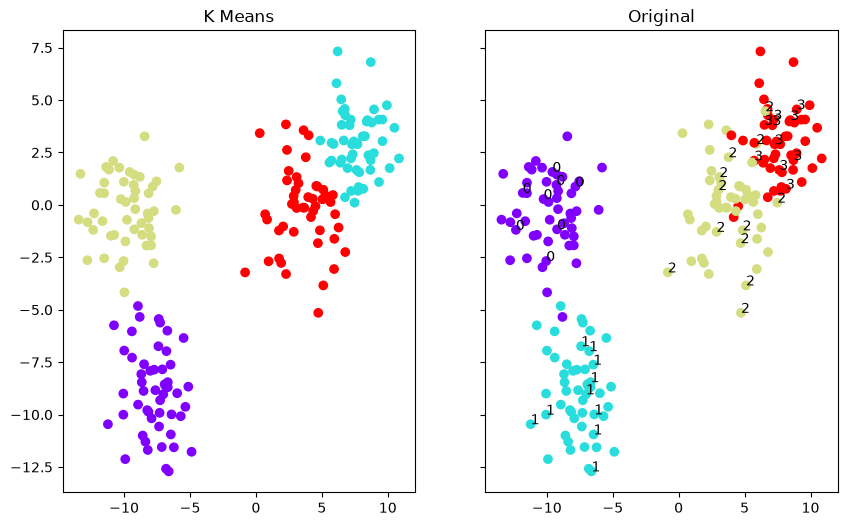

In [10]:
f, (ax1, ax2) = plt.subplots(1, 2, sharey = True, figsize = (10, 6))
ax1.set_title('K Means')
ax1.scatter(X[:, 0], X[:, 1], c = kmeans.labels_, cmap = 'rainbow')
ax2.set_title("Original")
ax2.scatter(X[:, 0], X[:, 1], c = y, cmap = 'rainbow')
for i, txt in enumerate(y):
    if i%5 == 0:
        plt.annotate(txt, (X[i, 0], X[i, 1]))

You should note that the colors are meaningless when in reference to the two plots.

##### Align K-Means prediction class with real values

In [11]:
y_pred = kmeans.predict(X)

In [12]:
y_pred

array([1, 0, 3, 0, 1, 2, 0, 2, 3, 3, 1, 1, 3, 1, 2, 1, 1, 1, 1, 2, 0, 3,
       1, 1, 0, 0, 3, 0, 3, 3, 1, 0, 1, 3, 1, 3, 0, 1, 0, 2, 1, 2, 1, 3,
       3, 3, 0, 0, 3, 0, 0, 3, 1, 1, 0, 3, 1, 3, 1, 2, 2, 2, 3, 3, 1, 2,
       0, 2, 2, 2, 3, 2, 3, 0, 0, 2, 2, 0, 0, 2, 1, 1, 2, 3, 0, 0, 1, 3,
       2, 0, 3, 1, 2, 3, 3, 1, 3, 2, 3, 3, 0, 1, 2, 0, 2, 3, 2, 3, 2, 2,
       1, 2, 2, 2, 3, 2, 3, 3, 0, 3, 1, 1, 1, 3, 0, 0, 1, 3, 2, 1, 0, 2,
       2, 0, 0, 0, 2, 2, 1, 0, 0, 0, 1, 3, 0, 1, 0, 2, 3, 2, 3, 3, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 0, 3, 1, 2, 0, 0, 1, 2, 3, 1, 1, 0, 3, 1,
       3, 0, 0, 2, 3, 0, 2, 2, 0, 2, 1, 1, 2, 3, 2, 3, 3, 0, 2, 1, 2, 0,
       2, 2], dtype=int32)

In [13]:
y

array([2, 1, 2, 1, 3, 0, 1, 0, 2, 2, 3, 3, 2, 3, 0, 3, 3, 3, 3, 0, 1, 2,
       3, 3, 1, 1, 3, 1, 2, 2, 3, 1, 3, 3, 3, 2, 1, 3, 1, 0, 3, 0, 3, 2,
       2, 2, 1, 1, 2, 1, 1, 2, 3, 3, 1, 2, 3, 2, 3, 0, 0, 0, 2, 2, 3, 0,
       1, 0, 0, 0, 2, 0, 2, 1, 1, 0, 0, 1, 1, 0, 2, 3, 0, 2, 1, 1, 3, 2,
       0, 1, 2, 3, 0, 2, 2, 3, 2, 0, 2, 2, 1, 3, 0, 1, 0, 2, 0, 2, 0, 0,
       3, 0, 0, 0, 2, 0, 2, 2, 1, 2, 3, 3, 3, 2, 1, 1, 3, 2, 0, 3, 1, 0,
       0, 1, 1, 1, 0, 0, 3, 1, 1, 1, 3, 2, 1, 3, 1, 0, 2, 0, 2, 2, 3, 3,
       2, 3, 3, 3, 0, 1, 1, 1, 1, 2, 3, 0, 1, 1, 3, 0, 2, 3, 3, 1, 2, 3,
       2, 1, 1, 0, 2, 1, 0, 0, 1, 0, 3, 3, 0, 2, 0, 3, 2, 1, 0, 2, 0, 1,
       0, 0])

In [14]:
y_pred = np.where(y_pred==0, 10, y_pred)
y_pred = np.where(y_pred==2, 0, y_pred)
y_pred = np.where(y_pred==3, 2, y_pred)
y_pred = np.where(y_pred==1, 3, y_pred)
y_pred = np.where(y_pred==10, 1, y_pred)

In [15]:
y_pred

array([3, 1, 2, 1, 3, 0, 1, 0, 2, 2, 3, 3, 2, 3, 0, 3, 3, 3, 3, 0, 1, 2,
       3, 3, 1, 1, 2, 1, 2, 2, 3, 1, 3, 2, 3, 2, 1, 3, 1, 0, 3, 0, 3, 2,
       2, 2, 1, 1, 2, 1, 1, 2, 3, 3, 1, 2, 3, 2, 3, 0, 0, 0, 2, 2, 3, 0,
       1, 0, 0, 0, 2, 0, 2, 1, 1, 0, 0, 1, 1, 0, 3, 3, 0, 2, 1, 1, 3, 2,
       0, 1, 2, 3, 0, 2, 2, 3, 2, 0, 2, 2, 1, 3, 0, 1, 0, 2, 0, 2, 0, 0,
       3, 0, 0, 0, 2, 0, 2, 2, 1, 2, 3, 3, 3, 2, 1, 1, 3, 2, 0, 3, 1, 0,
       0, 1, 1, 1, 0, 0, 3, 1, 1, 1, 3, 2, 1, 3, 1, 0, 2, 0, 2, 2, 3, 3,
       3, 3, 3, 3, 1, 1, 1, 1, 1, 2, 3, 0, 1, 1, 3, 0, 2, 3, 3, 1, 2, 3,
       2, 1, 1, 0, 2, 1, 0, 0, 1, 0, 3, 3, 0, 2, 0, 2, 2, 1, 0, 3, 0, 1,
       0, 0], dtype=int32)

#### Redo the visualizations

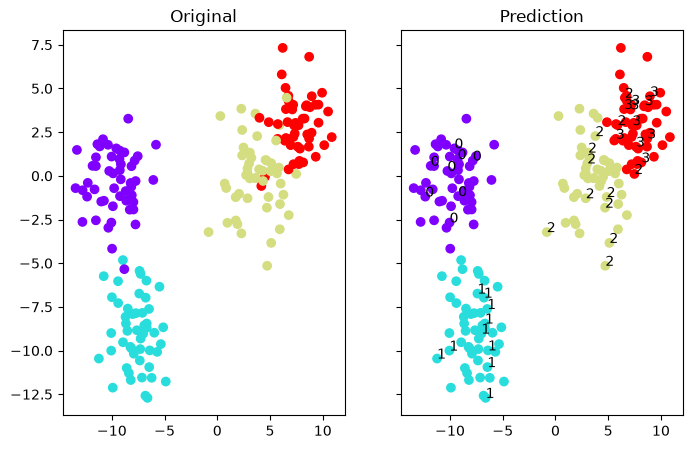

In [16]:
f, (ax1, ax2) = plt.subplots(1, 2, sharey = True, figsize = (8, 5))
ax1.set_title('Original')
ax1.scatter(X[:,0], X[:,1], c=y, cmap='rainbow')
ax2.set_title("Prediction")
ax2.scatter(X[:,0], X[:,1], c=y_pred, cmap='rainbow')
for i, txt in enumerate(y):
    if i%5 == 0:
        plt.annotate(txt, (X[i,0], X[i,1]))
plt.savefig("KMeans_pred.png")

#### Evaluate the model

In [17]:
print(confusion_matrix(y, y_pred))

[[49  1  0  0]
 [ 0 50  0  0]
 [ 0  0 46  4]
 [ 0  0  3 47]]


In [18]:
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.98      1.00      0.99        50
           2       0.94      0.92      0.93        50
           3       0.92      0.94      0.93        50

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.96      0.96      0.96       200



In [19]:
print(f"Homogeneity: {metrics.homogeneity_score(y, y_pred):.3f}")
print(f"Completeness: {metrics.completeness_score(y, y_pred):.3f}")
print(f"V-measure: {metrics.v_measure_score(y, y_pred):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(y, y_pred):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(y, y_pred):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, y_pred):.3f}")

Homogeneity: 0.891
Completeness: 0.891
V-measure: 0.891
Adjusted Rand Index: 0.898
Adjusted Mutual Information: 0.889
Silhouette Coefficient: 0.559


#### Conclusões
- Depois de alinhar as labels, o K-Means acerta em **96%** dos pontos (accuracy = 0.96). Os erros estão todos entre os clusters 2 e 3, que se sobrepõem no canto superior direito.
- O ARI (0.898) e a V-measure (0.891) confirmam um agrupamento muito próximo do real. O Silhouette (0.559) indica clusters razoavelmente compactos e separados.
- Os números dos clusters são arbitrários. Por isso é preciso alinhá-los com as classes reais antes de usar a matriz de confusão e o `classification_report`. As métricas de clustering (homogeneidade, ARI, AMI, ...) não dependem desse alinhamento.
- Para classificar pontos novos, o melhor é treinar um classificador sobre o resultado do clustering.